# Практична робота 4.5. Класифікація (набір даних Kaggle)

**Мета:** опанувати базові методи класифікації: підготовка даних, побудова моделі, оцінка якості.

**Набір даних:** Breast Cancer Wisconsin (Diagnostic) — є на Kaggle (`uciml/breast-cancer-wisconsin-data`), також вбудований у scikit-learn. 569 записів, 30 числових ознак, ціль — діагноз (злоякісна / доброякісна пухлина).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

data = load_breast_cancer(as_frame=True)
df = data.frame
df["target"] = df["target"].map({0: "malignant", 1: "benign"})
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


## 1. Попередня обробка
Перевіряємо пропуски і баланс класів. Категоріальних ознак немає, тому one-hot кодування не потрібне — кодуємо лише ціль (0/1).

Пропуски: 0
target
benign       357
malignant    212
Name: count, dtype: int64


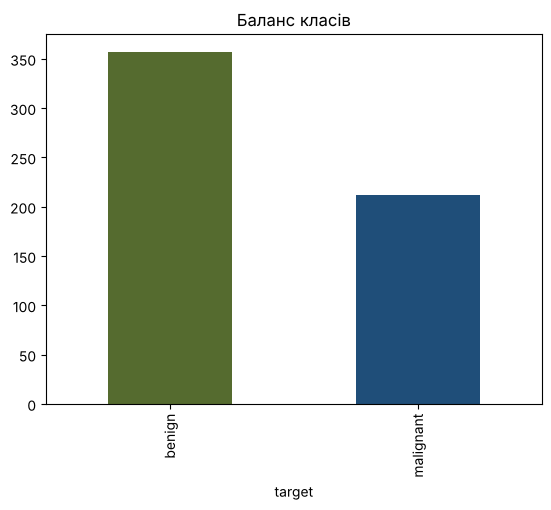

In [2]:
print("Пропуски:", df.isnull().sum().sum())
print(df["target"].value_counts())
df["target"].value_counts().plot(kind="bar", color=["#556b2f", "#1f4e79"], title="Баланс класів")
plt.show()

Класи помірно незбалансовані (≈63/37), тому при розбитті використовуємо стратифікацію.
## 2. Розподіл даних 80:20 і масштабування

In [3]:
X = df.drop(columns="target")
y = (df["target"] == "malignant").astype(int)   # 1 = злоякісна
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


## 3. Побудова моделей
Логістична регресія (базова модель) і Random Forest для порівняння.

In [4]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}
preds = {}
for name, m in models.items():
    m.fit(X_train_s, y_train)
    preds[name] = m.predict(X_test_s)
    print(f"=== {name}: accuracy = {accuracy_score(y_test, preds[name]):.3f}")
    print(classification_report(y_test, preds[name], target_names=["benign", "malignant"]))

=== Logistic Regression: accuracy = 0.965
              precision    recall  f1-score   support

      benign       0.96      0.99      0.97        72
   malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



=== Random Forest: accuracy = 0.965
              precision    recall  f1-score   support

      benign       0.95      1.00      0.97        72
   malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



## 4. Матриці помилок

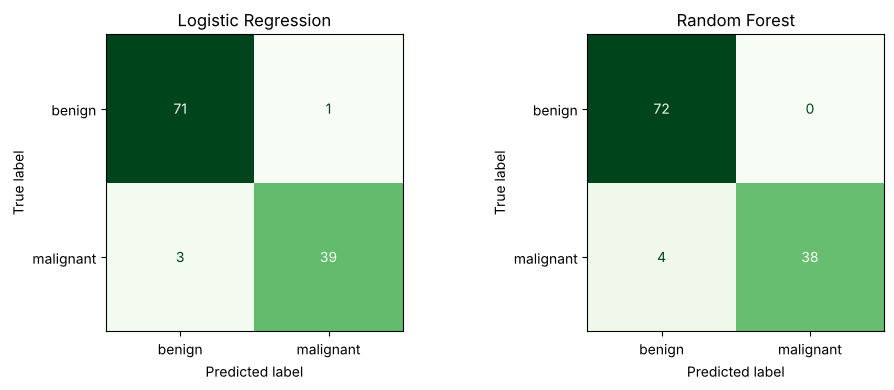

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["benign", "malignant"]).plot(ax=ax, cmap="Greens", colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 5. Важливість ознак (Random Forest)

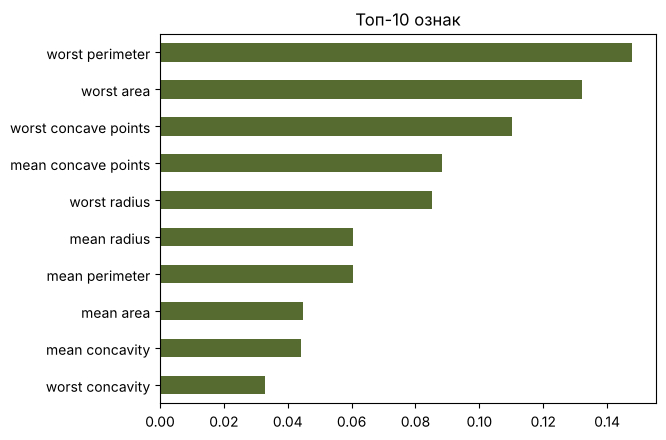

In [6]:
imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values().tail(10)
imp.plot(kind="barh", color="#556b2f", title="Топ-10 ознак")
plt.show()

## Висновки
1. Дані чисті (пропусків немає), класи помірно незбалансовані — застосовано стратифіковане розбиття 80:20.
2. Обидві моделі дають точність понад 95 %; логістична регресія на масштабованих даних не поступається Random Forest.
3. Для задачі важлива **recall класу malignant** (пропуск злоякісної пухлини — найдорожча помилка); матриця помилок показує лише поодинокі такі випадки.
4. Найінформативніші ознаки — характеристики розміру та форми ядер клітин (worst/mean concave points, perimeter, radius, area).